# Phase 3 · 1. Explore

Data: pull the derived sample and panel from R2 first (from the repo root, so `.env` is found):

```
uv run roundtrip sync --prefix sample/
uv run roundtrip sync --prefix panel/
```

`sample/trips/month=*/data.parquet` is the fixed-seed stratified trip sample (`sql/panel/trip_sample.sql`).
Strata are base x pickup borough x pickup hour, with up to `sample_rows_per_stratum` rows each, and
`sample_weight = n_stratum / rows kept`.

In [1]:
import json

import duckdb
import pandas as pd

from roundtrip.config import Settings

REPO = Settings().repo_dir                 # sql_dir is absolute, so this works from notebooks/
s = Settings(data_dir=REPO / "data")       # data_dir is relative by default; pin it to the repo

SAMPLE = (s.derived_dir / "sample" / "trips" / "month=*" / "data.parquet").as_posix()
PANEL = (s.derived_dir / "panel" / "zone_hour" / "month=*" / "data.parquet").as_posix()

con = duckdb.connect()
con.execute(f"CREATE VIEW sample AS SELECT * FROM read_parquet('{SAMPLE}', hive_partitioning=false)")
con.execute(f"CREATE VIEW panel  AS SELECT * FROM read_parquet('{PANEL}',  hive_partitioning=false)")


def q(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()


pd.set_option("display.width", 160, "display.max_columns", 50)
q("SELECT month, count(*) AS rows FROM sample GROUP BY 1 ORDER BY 1").T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44
month,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
rows,96996,96891,97052,96993,96984,96930,96851,96798,96904,96834,96780,96882,96766,96738,96796,96770,96842,96859,96807,96790,96746,96792,96804,96758,96774,96710,96807,96846,96863,96913,96933,96880,96824,96834,96962,97066,97032,97001,97091,97022,97183,97241,97248,97125,97047


### Adding some quick operations
Things to look at:
- rows counts and null rates by column and month
- wait-time distribution and date arithmetic (use quantile_cont?)
- invalid records: using case when or filter
- waits by zone and hour -- so join the zone lookup, date_trunc, grouping on several columns
- month-over-month change: CTEs, and window functions with lag
- ranking zones by wait within each borough: rank() / row_number() OVER etc
- rolling averages (ROWS between)
- driver pay vs fare, and trips per zone-hour as a supply proxy: multi-step CTEs

In [ ]:
# See the connection
# print("All columns:")
# print(q("DESCRIBE sample").column_name.tolist())

# print("Count columns:")
# print(len(q("DESCRIBE sample").column_name.tolist()))

# prettier printing
cols = q("DESCRIBE sample").column_name.tolist()
print(f"Sample has {len(cols)} columns. \n")


#print(q("SELECT * from sample"))
print("Counting rows")
print(q("SELECT count(*) from sample"))
print(q("SELECT count(trip_row) from sample"))

# null counts
#print(q("SELECT * FROM sample WHERE trip_row IS NULL"))
#for i in cols:
#    print(f"Null count of '{i}' is: ")
#    print(len(q(f"SELECT * FROM sample WHERE '{i}' IS NULL")))
#    print("\n")

# faster way to count
print("\nNull counts: ")
q("SELECT count(*) - count(COLUMNS(*)) FROM sample").T




Sample has 38 columns. 

Counting rows
   count_star()
0       4360765
   count(trip_row)
0          4360765

Null counts: 


,0
month,0
trip_row,0
base_code,0
base,0
dispatching_base_num,0
originating_base_num,2166812
request_datetime,0
on_scene_datetime,1260178
pickup_datetime,0
dropoff_datetime,0


In [48]:
# wait-time distribution
cols

['month',
 'trip_row',
 'base_code',
 'base',
 'dispatching_base_num',
 'originating_base_num',
 'request_datetime',
 'on_scene_datetime',
 'pickup_datetime',
 'dropoff_datetime',
 'pu_zone',
 'do_zone',
 'trip_miles',
 'trip_time',
 'base_passenger_fare',
 'tolls',
 'bcf',
 'sales_tax',
 'congestion_surcharge',
 'airport_fee',
 'tips',
 'driver_pay',
 'cbd_congestion_fee',
 'shared_request',
 'shared_match',
 'access_a_ride',
 'wav_request',
 'wav_match',
 'wait_seconds',
 'duration_seconds',
 'pu_borough',
 'pu_is_cbd',
 'pu_is_airport',
 'do_borough',
 'do_is_cbd',
 'do_is_airport',
 'n_stratum',
 'sample_weight']

## sample_weight

Three monthly totals:

- `w_sum`: sum of `sample_weight` in the sample
- `panel_trips`: sum of `n_trips` in the zone-hour panel. Same pickup-in-month filter, so this
  should match **exactly**, up to float error.
- `file_rows`: the manifest's raw-file row count. This includes pickups that fall outside the
  month, so it should only match **roughly**.

In [19]:
manifest = json.loads((REPO / "manifest.json").read_text())
file_rows = pd.Series({m: v["row_count"] for m, v in manifest["months"].items()}, name="file_rows")

w = q("""
    SELECT month,
           count(*)            AS sample_rows,
           sum(sample_weight)  AS w_sum,
           min(sample_weight)  AS w_min,
           max(sample_weight)  AS w_max
    FROM sample GROUP BY 1
""").set_index("month")
p = q("SELECT month, sum(n_trips) AS panel_trips FROM panel GROUP BY 1").set_index("month")

wt = w.join(p).join(file_rows).sort_index()
wt["vs_panel"] = wt.w_sum / wt.panel_trips - 1   # expect ~0 (float error)
wt["vs_file"] = wt.w_sum / wt.file_rows - 1      # expect small, negative (out-of-month pickups)
wt

,sample_rows,w_sum,w_min,w_max,panel_trips,file_rows,vs_panel,vs_file
month,,,,,,,,
2023-01,96996,1.847903e+07,1.0,1028.3725,18479031.0,18479031,-8.160139e-14,-8.160139e-14
2023-02,96891,1.796097e+07,1.0,1019.1300,17960971.0,17960971,3.130829e-14,3.130829e-14
2023-03,97052,2.041354e+07,1.0,1035.4025,20413539.0,20413539,-1.448841e-13,-1.448841e-13
2023-04,96993,1.914490e+07,1.0,951.3725,19144903.0,19144903,1.532108e-14,1.532108e-14
2023-05,96984,1.984768e+07,1.0,959.7475,19847676.0,19847676,-1.070255e-13,-1.070255e-13
2023-06,96930,1.936662e+07,1.0,918.8975,19366619.0,19366619,-3.330669e-16,-3.330669e-16
2023-07,96851,1.913213e+07,1.0,890.1550,19132131.0,19132131,-5.395684e-14,-5.395684e-14
2023-08,96798,1.832215e+07,1.0,820.9800,18322150.0,18322150,5.440093e-14,5.440093e-14
2023-09,96904,1.985112e+07,1.0,928.7825,19851123.0,19851123,-7.549517e-15,-7.549517e-15


In [20]:
# Flags: any row here needs an explanation before step 2.
bad_panel = wt[wt.vs_panel.abs() > 1e-9]
bad_file = wt[wt.vs_file.abs() > 0.01]   # TODO: pick the tolerance for "roughly"
print(f"{len(bad_panel)} months off vs panel, {len(bad_file)} months >1% off vs file")
bad_panel, bad_file

0 months off vs panel, 0 months >1% off vs file


(Empty DataFrame
 Columns: [sample_rows, w_sum, w_min, w_max, panel_trips, file_rows, vs_panel, vs_file]
 Index: [],
 Empty DataFrame
 Columns: [sample_rows, w_sum, w_min, w_max, panel_trips, file_rows, vs_panel, vs_file]
 Index: [])

In [21]:
# Within-stratum check: one weight per stratum, and weight x rows kept = n_stratum.
strata = q("""
    SELECT month, base, coalesce(pu_borough, 'Unknown') AS pu_borough,
           hour(pickup_datetime)         AS pickup_hour,
           count(*)                      AS kept,
           any_value(n_stratum)          AS n_stratum,
           count(DISTINCT sample_weight) AS n_distinct_w,
           sum(sample_weight)            AS w_sum
    FROM sample GROUP BY ALL
""")
strata["ok"] = (strata.n_distinct_w == 1) & ((strata.w_sum - strata.n_stratum).abs() < 1e-6)
print("strata failing:", (~strata.ok).sum(), "of", len(strata))
# Strata smaller than rows_per_stratum are kept whole (weight 1)
strata.assign(whole=strata.kept < s.sample_rows_per_stratum).groupby("month").whole.mean().to_frame(
    "share_strata_kept_whole"
).T

strata failing: 0 of 13024


month,2023-01,2023-02,2023-03,2023-04,2023-05,2023-06,2023-07,2023-08,2023-09,2023-10,2023-11,2023-12,2024-01,2024-02,2024-03,2024-04,2024-05,2024-06,2024-07,2024-08,2024-09,2024-10,2024-11,2024-12,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
share_strata_kept_whole,0.175258,0.16955,0.166667,0.172414,0.175258,0.172414,0.172414,0.166667,0.180887,0.172414,0.16955,0.172414,0.16955,0.16955,0.166667,0.16955,0.16955,0.166667,0.172414,0.166667,0.172414,0.172414,0.178082,0.16955,0.16955,0.183673,0.16955,0.166667,0.16955,0.166667,0.166667,0.172414,0.16955,0.166667,0.16955,0.172414,0.172414,0.16955,0.163763,0.172414,0.16955,0.166667,0.175258,0.16955,0.172414


,month,base,pu_borough,pickup_hour,kept,n_stratum,n_distinct_w,w_sum,ok
3532,2023-03,Uber,Manhattan,19,400,414161,1,414161.0,True
272,2023-01,Uber,Manhattan,18,400,411349,1,411349.0,True
10422,2023-02,Uber,Manhattan,18,400,407652,1,407652.0,True
1926,2023-01,Uber,Manhattan,19,400,404097,1,404097.0,True
11692,2023-03,Uber,Manhattan,20,400,403974,1,403974.0,True
10046,2023-03,Uber,Manhattan,18,400,402002,1,402002.0,True
9694,2024-01,Uber,Manhattan,18,400,398370,1,398370.0,True
3958,2023-02,Uber,Manhattan,19,400,398127,1,398127.0,True
10842,2023-03,Uber,Manhattan,21,400,396663,1,396663.0,True
12744,2024-02,Uber,Manhattan,18,400,391370,1,391370.0,True


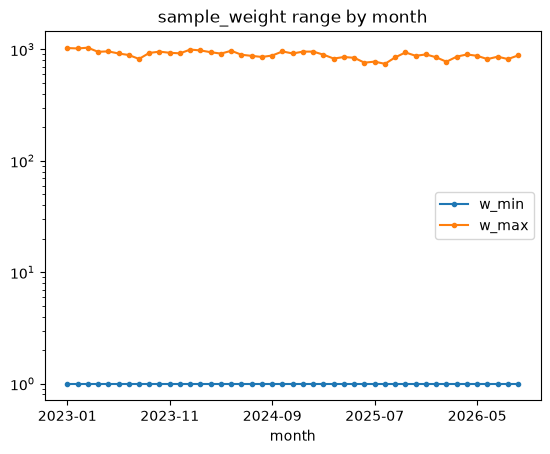

In [22]:
# Weight spread: a heavy weight means a few rows stand in for many trips.
wt[["w_min", "w_max"]].plot(logy=True, marker=".", title="sample_weight range by month")
strata.sort_values("n_stratum", ascending=False).head(10)

## Wait distribution

TODO: weighted quantiles and histogram of `wait_seconds`. The negative-wait share should be about 1.2%
(`validation.max_pickup_before_request_share` = 5%). Use the panel's `wait_ok` rule:
`0 <= wait <= s.validation.max_wait_seconds`.

In [23]:
q(f"""
    SELECT month,
           sum(sample_weight * (wait_seconds < 0)::INT) / sum(sample_weight)        AS neg_share,
           sum(sample_weight * (wait_seconds > {s.validation.max_wait_seconds})::INT)
               / sum(sample_weight)                                                 AS over_max_share,
           sum(sample_weight * (wait_seconds IS NULL)::INT) / sum(sample_weight)    AS null_share
    FROM sample GROUP BY 1 ORDER BY 1
""")

,month,neg_share,over_max_share,null_share
0,2023-01,0.011532,7.611059e-06,0.0
1,2023-02,0.010813,3.368373e-05,0.0
2,2023-03,0.009568,0.000000e+00,0.0
3,2023-04,0.007765,7.129443e-06,0.0
4,2023-05,0.009470,0.000000e+00,0.0
5,2023-06,0.009207,5.163524e-08,0.0
6,2023-07,0.008648,0.000000e+00,0.0
7,2023-08,0.009351,1.091575e-07,0.0
8,2023-09,0.009570,1.007500e-07,0.0
9,2023-10,0.010289,0.000000e+00,0.0


## driver_pay

TODO: units (dollars per trip?), zeros, negatives, outliers (the validation p99.9 band is
`pay_p999_min`/`pay_p999_max`), and whether tips are included. Compare with `tips` and `base_passenger_fare`.

In [24]:
q("""
    SELECT month,
           sum(sample_weight * (driver_pay = 0)::INT) / sum(sample_weight) AS zero_share,
           sum(sample_weight * (driver_pay < 0)::INT) / sum(sample_weight) AS neg_share,
           quantile_cont(driver_pay, [0.01, 0.5, 0.99, 0.999])              AS q_unweighted
    FROM sample GROUP BY 1 ORDER BY 1
""")

,month,zero_share,neg_share,q_unweighted
0,2023-01,0.015860,8.541979e-06,"[0.0, 11.86, 65.511, 117.4432]"
1,2023-02,0.013741,2.082766e-05,"[0.0, 12.39, 68.492, 123.5572]"
2,2023-03,0.018182,4.898710e-08,"[0.0, 13.03, 72.9098, 123.15388]"
3,2023-04,0.001471,0.000000e+00,"[5.39, 13.79, 77.14, 141.11048]"
4,2023-05,0.001451,3.204090e-05,"[5.39, 14.23, 77.6868, 136.94017]"
5,2023-06,0.001162,0.000000e+00,"[5.39, 13.87, 78.3026, 145.79917]"
6,2023-07,0.001115,0.000000e+00,"[5.39, 13.61, 76.12, 143.943]"
7,2023-08,0.000730,7.723439e-06,"[5.39, 13.54, 76.8306, 139.50624]"
8,2023-09,0.000261,5.148122e-05,"[5.39, 14.17, 79.6091, 139.88485]"
9,2023-10,0.000150,7.550369e-05,"[5.39, 14.12, 77.5267, 133.44342]"


## January 2025 schema change

`cbd_congestion_fee` is NULL in every file before 2025-01 (`sql/views/trips.sql`). TODO: list every
column whose null rate or level breaks at 2025-01, and keep all of them out of the features.

In [25]:
cols = [c for c in q("DESCRIBE sample").column_name if c != "month"]
nulls = q(
    "SELECT month, "
    + ", ".join(f'avg(("{c}" IS NULL)::INT) AS "{c}"' for c in cols)
    + " FROM sample GROUP BY 1 ORDER BY 1"
).set_index("month")
pre, post = nulls[nulls.index < "2025-01"].mean(), nulls[nulls.index >= "2025-01"].mean()
(post - pre).loc[lambda d: d.abs() > 0.01].sort_values()   # null-rate breaks at 2025-01

cbd_congestion_fee   -1.000000
on_scene_datetime    -0.446367
dtype: float64

## Known at request time

Wait-time features: pickup zone, hour, day of week, base. Fill this in, then copy it into the
`features.sql` header.

| column | known at request? | note |
|---|---|---|
| pu_zone | yes | |
| hour / day of week | yes | take them from `request_datetime`, not pickup? |
| base | yes | |
| do_zone | ? | |
| trip_miles, trip_time, fares, driver_pay, tips | no | outcomes / post-trip |
| cbd_congestion_fee | no | 2025 on only |